# Which factors make a Test bowler's average low?

The earlier analysis (`Test Bowler Average Analysis.ipynb`) mostly restated the definition of the average:
average = strike rate × economy ÷ 6, and "removes batters before they're set" is runs conceded per wicket
in other words. This notebook asks the question in a way that can't be answered by arithmetic.

**Design rules**

1. **Context is valued from everyone else.** Each delivery gets a context-expected wicket probability and
   expected runs from models trained on every other bowler's deliveries (cross-fitted by bowler), using only
   things known before the ball is bowled.
2. **Skill claims must survive out of sample.** A trait measured on wickets 1–25 only counts if it predicts
   how the bowler does on wickets 26–50.
3. **Mechanical stats (strike rate, economy, dots, maidens) are never explanatory features.**

**Scope:** international Tests only (Cricsheet `match_type == "Test"`, `team_type == "international"`, national
sides only), each bowler's **first 50 Test wickets** (core results repeated at 100), bowlers whose first Test in the data is on
or after 2007-01-01 so that wicket 1 really is their first.

## 0. Setup

In [1]:
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse, stats
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor, RidgeCV
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss, mean_poisson_deviance, r2_score

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

PROJECT_DIR = Path.cwd()
JSON_DIR = PROJECT_DIR / 'all_male_json'
CACHE_DIR = PROJECT_DIR / 'cache'
CACHE_DIR.mkdir(exist_ok=True)

WICKET_WINDOW = 50                 # each bowler is measured over their first N Test wickets
SENSITIVITY_WINDOW = 100           # the core results are repeated at this N
RESULTS_FILE = 'factor_results.json'   # read by the HTML report
FULL_COVERAGE_FROM = pd.Timestamp('2007-01-01')   # Cricsheet's Test coverage is patchy before this

# Dismissals credited to the bowler (run outs, retirements, obstruction etc. are not)
BOWLER_WICKET_KINDS = ('caught', 'bowled', 'lbw', 'caught and bowled', 'stumped', 'hit wicket')
NON_DISMISSAL_KINDS = ('retired hurt', 'retired not out')
# Full-member national sides; anything else (e.g. ICC World XI) is not a national team
NATIONAL_TEAMS = {'Australia', 'England', 'India', 'Pakistan', 'South Africa', 'New Zealand', 'Sri Lanka',
                  'West Indies', 'Bangladesh', 'Zimbabwe', 'Afghanistan', 'Ireland'}

N_BOOT = 1000
RNG = np.random.default_rng(42)

## 1. Parse every international Test

One row per delivery, with the fields the old parser dropped: fielders, DRS reviews, toss, umpires, declarations
and the event name (used to find the host country). Parsed once and cached in `cache/`.

In [2]:
PARSE_CACHE = CACHE_DIR / 'test_deliveries.pkl'

def parse_tests(json_dir):
    deliveries, dismissals, matches = [], [], []

    for file_path in sorted(json_dir.glob('*.json')):
        with open(file_path, 'r') as f:
            match_data = json.load(f)

        info = match_data.get('info', {})
        teams = info.get('teams', [])
        if info.get('match_type') != 'Test' or info.get('team_type') != 'international':
            continue
        if not set(teams) <= NATIONAL_TEAMS:
            continue

        match_id = int(file_path.stem)
        registry = info.get('registry', {}).get('people', {})
        outcome = info.get('outcome', {})
        toss = info.get('toss', {})
        umpires = info.get('officials', {}).get('umpires', [])

        matches.append({
            'match_id': match_id,
            'test_number': info.get('match_type_number'),
            'date': info.get('dates', [None])[0],
            'n_days_listed': len(info.get('dates', [])),
            'venue': info.get('venue'),
            'city': info.get('city'),
            'event': (info.get('event') or {}).get('name'),
            'team_1': teams[0],
            'team_2': teams[1],
            'toss_winner': toss.get('winner'),
            'toss_decision': toss.get('decision'),
            'umpire_1': umpires[0] if len(umpires) > 0 else None,
            'umpire_2': umpires[1] if len(umpires) > 1 else None,
            'winner': outcome.get('winner'),
            'result': outcome.get('result', 'win' if outcome.get('winner') else None),
        })

        for innings_num, innings in enumerate(match_data.get('innings', []), start=1):
            batting_team = innings.get('team')
            bowling_team = [t for t in teams if t != batting_team][0]
            declared = int(bool(innings.get('declared')))

            for over in innings.get('overs', []):
                over_num = over.get('over')

                for ball_num, delivery in enumerate(over.get('deliveries', []), start=1):
                    extras = delivery.get('extras', {})
                    runs = delivery.get('runs', {})
                    wickets = delivery.get('wickets', [])
                    review = delivery.get('review', {})
                    bowler_wicket = next((w for w in wickets if w.get('kind') in BOWLER_WICKET_KINDS), None)
                    first_wicket = wickets[0] if wickets else None
                    w = bowler_wicket or first_wicket or {}

                    deliveries.append({
                        'match_id': match_id,
                        'batting_team': batting_team,
                        'bowling_team': bowling_team,
                        'innings': innings_num,
                        'innings_declared': declared,
                        'over': over_num,
                        'ball': ball_num,
                        'bowler_id': registry.get(delivery.get('bowler')),
                        'bowler': delivery.get('bowler'),
                        'batter_id': registry.get(delivery.get('batter')),
                        'batter': delivery.get('batter'),
                        'non_striker_id': registry.get(delivery.get('non_striker')),
                        'runs_batter': runs.get('batter', 0),
                        'runs_total': runs.get('total', 0),
                        'wides': extras.get('wides', 0),
                        'noballs': extras.get('noballs', 0),
                        'byes': extras.get('byes', 0),
                        'legbyes': extras.get('legbyes', 0),
                        'penalty': extras.get('penalty', 0),
                        'is_wicket': int(bowler_wicket is not None),
                        'any_dismissal': int(any(x.get('kind') not in NON_DISMISSAL_KINDS for x in wickets)),
                        'wicket_kind': w.get('kind'),
                        'player_out_id': registry.get(w.get('player_out')),
                        'fielder': (w.get('fielders') or [{}])[0].get('name'),
                        'fielder_sub': int(bool((w.get('fielders') or [{}])[0].get('substitute'))),
                        'review_by': review.get('by'),
                        'review_decision': review.get('decision'),
                        'review_umpires_call': int(bool(review.get('umpires_call'))),
                    })

                    for x in wickets:
                        dismissals.append({
                            'match_id': match_id, 'innings': innings_num, 'over': over_num, 'ball': ball_num,
                            'player_out_id': registry.get(x.get('player_out')), 'kind': x.get('kind'),
                        })

    matches = pd.DataFrame(matches)
    matches['date'] = pd.to_datetime(matches['date'])
    df = pd.DataFrame(deliveries).merge(matches[['match_id', 'date', 'venue']], on='match_id')
    df = df.sort_values(['date', 'match_id', 'innings', 'over', 'ball']).reset_index(drop=True)
    df['seq'] = np.arange(len(df))
    dismissals = pd.DataFrame(dismissals)
    return df, dismissals, matches


if PARSE_CACHE.exists():
    with open(PARSE_CACHE, 'rb') as f:
        df, dismissals, matches = pickle.load(f)
else:
    df, dismissals, matches = parse_tests(JSON_DIR)
    with open(PARSE_CACHE, 'wb') as f:
        pickle.dump((df, dismissals, matches), f)

print(f'{len(matches)} international Tests, {len(df):,} deliveries')
print('Date range:', matches['date'].min().date(), 'to', matches['date'].max().date())

893 international Tests, 1,719,653 deliveries
Date range: 2001-12-19 to 2026-08-27


## 2. Context for every delivery, known before it is bowled

- **Batter:** pre-match Test average (shrunk toward the batting position's norm) and strike rate, Tests played,
  batting position, hand, balls faced so far this innings.
- **Opposition line-up:** mean pre-match average of the batting side's best seven. This is fixed before the
  match. Which batter is at the crease is kept separate, because a bowler who removes the top order then bowls
  at the tail.
- **Ball and phase:** overs since the new ball (assumed taken at 80), innings 1–4, overs into the match (≈ day).
- **Match state:** bowling side's lead, wickets down, follow-on.
- **Venue:** host country from the event name ("India tour of Australia"), then from other events at the
  same ground; home / away / neutral for the bowler; UAE treated as neutral. Toss.
- **Era and officials:** year, whether DRS reviews were recorded, the umpires' LBW rate in *other* matches.
- **Role and usage:** opening the bowling, over number within the spell (a spell breaks after a gap of
  more than one over from that bowler), spell number, overs already bowled in the match.
- **Bowling partner:** the bowler at the other end and their pre-match average.

In [3]:
# ---- basic per-ball quantities -------------------------------------------------------------
df['is_legal'] = ((df['wides'] == 0) & (df['noballs'] == 0)).astype(int)
df['ball_faced'] = (df['wides'] == 0).astype(int)          # no-balls count as faced, wides don't
df['bowler_runs'] = df['runs_total'] - df['byes'] - df['legbyes'] - df['penalty']
df['year'] = df['date'].dt.year

# ---- batting position: order of first appearance at the crease in each innings -------------
appear = pd.concat([
    df[['match_id', 'innings', 'seq', 'batter_id']].rename(columns={'batter_id': 'pid'}),
    df[['match_id', 'innings', 'seq', 'non_striker_id']].rename(columns={'non_striker_id': 'pid'}),
]).sort_values('seq').drop_duplicates(['match_id', 'innings', 'pid'])
appear['batting_position'] = appear.groupby(['match_id', 'innings']).cumcount() + 1
df = df.merge(appear[['match_id', 'innings', 'pid', 'batting_position']]
              .rename(columns={'pid': 'batter_id'}), on=['match_id', 'innings', 'batter_id'], how='left')

# ---- batter state within the innings, before this ball -------------------------------------
g = df.groupby(['match_id', 'innings', 'batter_id'])
df['batter_balls_before'] = g['ball_faced'].cumsum() - df['ball_faced']
df['batter_runs_before'] = g['runs_batter'].cumsum() - df['runs_batter']

# ---- batter quality entering the match (prior Tests in the data only) ----------------------
outs = (dismissals[~dismissals['kind'].isin(NON_DISMISSAL_KINDS)]
        .groupby(['match_id', 'player_out_id']).size().rename('outs').reset_index()
        .rename(columns={'player_out_id': 'batter_id'}))
batter_match = (df.groupby(['batter_id', 'match_id'])
                .agg(runs=('runs_batter', 'sum'), balls=('ball_faced', 'sum'), date=('date', 'first'))
                .reset_index().merge(outs, on=['match_id', 'batter_id'], how='left'))
batter_match['outs'] = batter_match['outs'].fillna(0)
batter_match = batter_match.sort_values(['batter_id', 'date', 'match_id'])
for c in ['runs', 'balls', 'outs']:
    batter_match[f'prior_{c}'] = batter_match.groupby('batter_id')[c].cumsum() - batter_match[c]
batter_match['prior_tests'] = batter_match.groupby('batter_id').cumcount()
df = df.merge(batter_match[['batter_id', 'match_id', 'prior_runs', 'prior_balls', 'prior_outs', 'prior_tests']]
              .rename(columns={'prior_tests': 'batter_prior_tests'}), on=['batter_id', 'match_id'], how='left')

def position_band(pos):
    return np.select([pos <= 2, pos <= 4, pos <= 7], ['opener', 'top 3-4', 'middle 5-7'], 'tail 8-11')

df['batter_band'] = position_band(df['batting_position'])
# Shrink toward the typical average for the batting position (5 pseudo-dismissals), as in the old notebook
band_avg = df.groupby('batter_band').apply(
    lambda x: x['runs_batter'].sum() / x['any_dismissal'].sum(), include_groups=False)
K_SHRINK = 5
df['batter_prior_avg'] = ((df['prior_runs'] + K_SHRINK * df['batter_band'].map(band_avg))
                          / (df['prior_outs'] + K_SHRINK))
df['batter_prior_sr'] = ((df['prior_runs'] + 0.5 * 300) / (df['prior_balls'] + 300) * 100)   # shrunk toward 50

# Opposition line-up strength, fixed before the match: mean pre-match average of the batting side's best 7.
# This is what the bowler is dealt. Which of those batters is at the crease on a given ball is partly
# the bowler's own doing (dismiss the top order and you bowl at the tail), so it is kept separate.
bat_xi = df.groupby(['match_id', 'batting_team', 'batter_id'])['batter_prior_avg'].first().reset_index()
lineup = (bat_xi.sort_values('batter_prior_avg', ascending=False).groupby(['match_id', 'batting_team'])
          .head(7).groupby(['match_id', 'batting_team'])['batter_prior_avg'].mean().rename('lineup_avg'))
df = df.merge(lineup.reset_index(), on=['match_id', 'batting_team'], how='left')
df['batter_vs_lineup'] = df['batter_prior_avg'] - df['lineup_avg']

# ---- batter and bowler metadata (scraped from Cricinfo by scrape_player_styles.py) ---------
player_styles = pd.read_csv('player_styles.csv').drop_duplicates('identifier').set_index('identifier')
player_styles['date_of_birth'] = pd.to_datetime(player_styles['date_of_birth'], errors='coerce', format='mixed')

def parse_batting_hand(s):
    if not isinstance(s, str): return None
    s = s.lower()
    return 'left' if 'left' in s else ('right' if 'right' in s else None)

SPIN_TYPES = ('offbreak', 'legbreak', 'orthodox', 'googly', 'chinaman', 'unorthodox', 'wrist')

def parse_bowling_style(s):
    """Return (arm, is_spinner) from the first listed bowling style, e.g. 'right-arm fast-medium, legbreak'."""
    if not isinstance(s, str): return (None, None)
    first = s.split(',')[0].lower()
    arm = 'left' if 'left-arm' in first or first.startswith('slow left') else 'right'
    return (arm, int(any(t in first for t in SPIN_TYPES) or first.startswith('slow left')))

df['batter_hand'] = df['batter_id'].map(player_styles['batting_style']).map(parse_batting_hand).fillna('unknown')

# ---- ball age, phase and pitch wear --------------------------------------------------------
# The new ball is due after 80 overs; assume it is taken then (the data doesn't record it)
df['ball_age_overs'] = np.where(df['over'] < 80, df['over'], (df['over'] - 80) % 80)
df['second_new_ball'] = (df['over'] >= 80).astype(int)
df['match_ball'] = df.groupby('match_id')['is_legal'].cumsum() - df['is_legal']
df['match_over'] = df['match_ball'] // 6            # overs bowled in the match before this ball (~90 per day)

# ---- match state, before this ball ---------------------------------------------------------
df['innings_runs_before'] = df.groupby(['match_id', 'innings'])['runs_total'].cumsum() - df['runs_total']
df['innings_wkts_before'] = df.groupby(['match_id', 'innings'])['any_dismissal'].cumsum() - df['any_dismissal']
inn_tot = df.groupby(['match_id', 'innings']).agg(team=('batting_team', 'first'), runs=('runs_total', 'sum')).reset_index()
prev = []
for mid, grp in inn_tot.groupby('match_id'):
    for _, r in grp.iterrows():
        earlier = grp[grp['innings'] < r['innings']]
        prev.append({'match_id': mid, 'innings': r['innings'],
                     'bat_prev_runs': earlier.loc[earlier['team'] == r['team'], 'runs'].sum(),
                     'bowl_prev_runs': earlier.loc[earlier['team'] != r['team'], 'runs'].sum()})
df = df.merge(pd.DataFrame(prev), on=['match_id', 'innings'], how='left')
# Bowling team's lead (positive = ahead). In the 4th innings this is runs still needed minus one.
df['bowling_lead'] = df['bowl_prev_runs'] - df['bat_prev_runs'] - df['innings_runs_before']
inn2_team = inn_tot[inn_tot['innings'] == 2].set_index('match_id')['team']
df['follow_on'] = ((df['innings'] == 3) & (df['batting_team'] == df['match_id'].map(inn2_team))).astype(int)

# ---- toss, venue country and home advantage ------------------------------------------------
matches['place'] = matches['city'].fillna(matches['venue'].str.split(',').str[-1].str.strip())
# Host country, in order of preference:
#   1. the event name ("India tour of Australia", "England in India Test Series")
#   2. the host most often named by events at the same place (covers trophy series like The Ashes)
#   3. the team in at least 75% of the place's Tests (3+ Tests needed)
# The UAE (Pakistan's and Afghanistan's adopted home) is treated as neutral.
def host_from_event(r):
    ev = r['event'] if isinstance(r['event'], str) else ''
    hits = [t for t in (r['team_1'], r['team_2']) if f'tour of {t}' in ev or f' in {t}' in ev]
    if not hits and ' v ' in ev:           # "Sri Lanka v Bangladesh": home side is named first
        hits = [t for t in (r['team_1'], r['team_2']) if ev.startswith(t)]
    return hits[0] if len(hits) == 1 else None
matches['host_event'] = matches.apply(host_from_event, axis=1)
host_place_event = matches.dropna(subset=['host_event']).groupby('place')['host_event'].agg(lambda s: s.mode().iloc[0])
long = pd.concat([matches[['match_id', 'place', 'team_1']].rename(columns={'team_1': 'team'}),
                  matches[['match_id', 'place', 'team_2']].rename(columns={'team_2': 'team'})])
n_place = matches.groupby('place').size()
share = long.groupby(['place', 'team']).size() / n_place
share = share[(share >= 0.75) & (share.index.get_level_values('place').map(n_place) >= 3)]
host_place_share = share.sort_values(ascending=False).reset_index().drop_duplicates('place').set_index('place')['team']
fallback = matches['place'].map(host_place_event).fillna(matches['place'].map(host_place_share))
fallback = fallback.where(fallback.eq(matches['team_1']) | fallback.eq(matches['team_2']))
is_uae = (matches['place'] + ' ' + matches['venue']).str.contains('Dubai|Sharjah|Abu Dhabi')
matches['host'] = matches['host_event'].fillna(fallback).where(~is_uae)
print('Tests treated as neutral:', matches['host'].isna().sum(), '-',
      sorted(matches.loc[matches['host'].isna(), 'place'].unique()))
df = df.merge(matches[['match_id', 'host', 'toss_winner', 'toss_decision', 'umpire_1', 'umpire_2']], on='match_id')
df['venue_for_bowler'] = np.select(
    [df['host'] == df['bowling_team'], df['host'] == df['batting_team']], ['home', 'away'], 'neutral')
df['host_country'] = df['host'].fillna('Neutral')
df['bowled_first_by_choice'] = ((df['toss_winner'] == df['bowling_team']) & (df['toss_decision'] == 'field')).astype(int)

# ---- officials and DRS ----------------------------------------------------------------------
drs_matches = set(df.loc[df['review_by'].notna(), 'match_id'])
df['drs_in_use'] = df['match_id'].isin(drs_matches).astype(int)
m_lbw = df.groupby('match_id').agg(lbw=('wicket_kind', lambda s: (s == 'lbw').sum()), balls=('is_legal', 'sum'))
m_ump = matches.set_index('match_id')[['umpire_1', 'umpire_2']].join(m_lbw)
ump_long = pd.concat([m_ump[['umpire_1', 'lbw', 'balls']].rename(columns={'umpire_1': 'ump'}),
                      m_ump[['umpire_2', 'lbw', 'balls']].rename(columns={'umpire_2': 'ump'})]).dropna(subset=['ump'])
ump_tot = ump_long.groupby('ump')[['lbw', 'balls']].sum()
league_lbw = m_lbw['lbw'].sum() / m_lbw['balls'].sum()
def ump_rate(u, mid):   # umpire's LBW rate in all OTHER matches, shrunk toward the league rate
    if pd.isna(u) or u not in ump_tot.index: return league_lbw
    lbw = ump_tot.at[u, 'lbw'] - m_ump.at[mid, 'lbw']; balls = ump_tot.at[u, 'balls'] - m_ump.at[mid, 'balls']
    return (lbw + league_lbw * 20000) / (balls + 20000)
m_ump['umpire_lbw_rate'] = [np.mean([ump_rate(r.umpire_1, mid), ump_rate(r.umpire_2, mid)]) for mid, r in m_ump.iterrows()]
df['umpire_lbw_index'] = df['match_id'].map(m_ump['umpire_lbw_rate']) / league_lbw

# ---- bowler usage: opener, spells, workload ------------------------------------------------
bo = (df.groupby(['match_id', 'innings', 'bowler_id', 'over'], sort=False)
      .agg(seq=('seq', 'first')).reset_index().sort_values('seq'))
bo['gap'] = bo.groupby(['match_id', 'innings', 'bowler_id'])['over'].diff()
bo['new_spell'] = (bo['gap'].isna() | (bo['gap'] > 2)).astype(int)
bo['spell_no'] = bo.groupby(['match_id', 'innings', 'bowler_id'])['new_spell'].cumsum()
bo['over_in_spell'] = bo.groupby(['match_id', 'innings', 'bowler_id', 'spell_no']).cumcount() + 1
bo['match_overs_before'] = bo.groupby(['match_id', 'bowler_id']).cumcount()
openers = bo[bo['over'] <= 1].groupby(['match_id', 'innings'])['bowler_id'].apply(set)
bo['is_opener'] = [int(b in openers.get((m, i), set())) for m, i, b in zip(bo['match_id'], bo['innings'], bo['bowler_id'])]
# Bowler at the other end: whoever bowled the previous over of the innings
inn_overs = bo.sort_values('seq').groupby(['match_id', 'innings'])
bo['partner_id'] = inn_overs['bowler_id'].shift(1)
bo.loc[bo['partner_id'] == bo['bowler_id'], 'partner_id'] = None
df = df.merge(bo[['match_id', 'innings', 'bowler_id', 'over', 'spell_no', 'over_in_spell',
                  'match_overs_before', 'is_opener', 'partner_id']],
              on=['match_id', 'innings', 'bowler_id', 'over'], how='left')

# Partner quality: the partner's bowling average entering the match (shrunk with 10 pseudo-wickets)
bm = (df.groupby(['bowler_id', 'match_id']).agg(runs=('bowler_runs', 'sum'), wkts=('is_wicket', 'sum'), date=('date', 'first'))
      .reset_index().sort_values(['bowler_id', 'date', 'match_id']))
for c in ['runs', 'wkts']:
    bm[f'prior_{c}'] = bm.groupby('bowler_id')[c].cumsum() - bm[c]
LEAGUE_AVG = df['bowler_runs'].sum() / df['is_wicket'].sum()
bm['prior_bowl_avg'] = (bm['prior_runs'] + 10 * LEAGUE_AVG) / (bm['prior_wkts'] + 10)
df = df.merge(bm[['bowler_id', 'match_id', 'prior_bowl_avg']].rename(
    columns={'bowler_id': 'partner_id', 'prior_bowl_avg': 'partner_prior_avg'}), on=['partner_id', 'match_id'], how='left')
df['partner_prior_avg'] = df['partner_prior_avg'].fillna(LEAGUE_AVG)

# ---- bowler profile --------------------------------------------------------------------------
arm_spin = df['bowler_id'].map(player_styles['bowling_style']).map(parse_bowling_style)
df['bowler_arm'] = arm_spin.str[0].fillna('unknown')
df['is_spinner'] = arm_spin.str[1]
df['bowler_type'] = np.select([df['is_spinner'] == 1, df['is_spinner'] == 0], ['spin', 'pace'], 'unknown')

df = df.sort_values('seq').reset_index(drop=True)
print(f'League runs per wicket: {LEAGUE_AVG:.2f}')
print('Bowlers missing a style:', df.loc[df['bowler_type'] == 'unknown', 'bowler_id'].nunique(),
      'of', df['bowler_id'].nunique(), '| share of balls:', round((df['bowler_type'] == 'unknown').mean(), 4))
print(df['venue_for_bowler'].value_counts(normalize=True).round(3))

Tests treated as neutral: 36 - ['Abu Dhabi', 'Dubai International Cricket Stadium', 'Leeds', 'London', 'Sharjah Cricket Stadium', 'Southampton']
League runs per wicket: 32.35
Bowlers missing a style: 31 of 790 | share of balls: 0.005
venue_for_bowler
home       0.480
away       0.474
neutral    0.046
Name: proportion, dtype: float64


## 3. Each bowler's first 50 Test wickets

In [4]:
first_test = df.groupby('bowler_id')['date'].min()
career_wkts = df.groupby('bowler_id')['is_wicket'].sum()

def build_windows(n_wickets):
    """Every delivery from a bowler's first Test up to and including the ball of their Nth wicket.

    Only bowlers whose first Test in the data is on or after FULL_COVERAGE_FROM are eligible, so that
    wicket 1 really is the bowler's first Test wicket (left-censoring rule from the old notebook).
    """
    eligible = career_wkts[(career_wkts >= n_wickets) & (first_test >= FULL_COVERAGE_FROM)].index
    w = df[df['bowler_id'].isin(eligible)].copy()
    w['wickets_taken'] = w.groupby('bowler_id')['is_wicket'].cumsum()
    w = w[w['wickets_taken'] - w['is_wicket'] < n_wickets].copy()
    # Halves for the split-half test: wickets 1..N/2 and N/2+1..N
    w['half'] = np.where(w['wickets_taken'] - w['is_wicket'] < n_wickets // 2, 1, 2)
    assert (w.groupby('bowler_id')['is_wicket'].sum() == n_wickets).all()
    assert (w[w['half'] == 1].groupby('bowler_id')['is_wicket'].sum() == n_wickets // 2).all()
    return w

win = build_windows(WICKET_WINDOW)

def summarise(w):
    s = w.groupby('bowler_id').agg(
        bowler=('bowler', 'first'), team=('bowling_team', 'first'), bowler_type=('bowler_type', 'first'),
        bowler_arm=('bowler_arm', 'first'), first_test=('date', 'min'), tests=('match_id', 'nunique'),
        runs=('bowler_runs', 'sum'), wkts=('is_wicket', 'sum'), legal=('is_legal', 'sum'))
    s['average'] = s['runs'] / s['wkts']
    s['strike_rate'] = s['legal'] / s['wkts']
    s['economy'] = 6 * s['runs'] / s['legal']
    assert np.allclose(s['average'], s['strike_rate'] * s['economy'] / 6)
    return s

bowlers = summarise(win)
dob = bowlers.index.map(player_styles['date_of_birth'])
bowlers['age_at_debut'] = (bowlers['first_test'] - pd.Series(dob, index=bowlers.index)).dt.days / 365.25
print(f'{len(bowlers)} bowlers reached {WICKET_WINDOW} Test wickets with a first Test on or after '
      f'{FULL_COVERAGE_FROM.date()} ({(bowlers.bowler_type == "spin").sum()} spin, '
      f'{(bowlers.bowler_type == "pace").sum()} pace, {(bowlers.bowler_type == "unknown").sum()} unknown)')
print(f'Average over the first {WICKET_WINDOW}: median {bowlers.average.median():.1f}, '
      f'range {bowlers.average.min():.1f}-{bowlers.average.max():.1f}')
bowlers.sort_values('average')[['bowler', 'team', 'bowler_type', 'tests', 'average', 'strike_rate', 'economy']].head(8)

109 bowlers reached 50 Test wickets with a first Test on or after 2007-01-01 (40 spin, 69 pace, 0 unknown)
Average over the first 50: median 31.1, range 13.7-48.6


,bowler,team,bowler_type,tests,average,strike_rate,economy
bowler_id,,,,,,,
cfe70281,VD Philander,South Africa,pace,7,13.68,24.80,3.309677
68c56d09,KA Jamieson,New Zealand,pace,9,14.86,37.30,2.390349
a089f93f,Mohammad Abbas,Pakistan,pace,10,16.66,41.60,2.402885
2e171977,AR Patel,India,spin,12,17.06,44.10,2.321088
d167edd3,SM Boland,Australia,pace,13,18.64,40.30,2.775186
a8e56914,D Olivier,South Africa,pace,11,18.96,29.72,3.827725
0f3ee070,OE Robinson,England,pace,11,19.96,44.38,2.698513
8d2c70ad,Kuldeep Yadav,India,spin,12,21.44,37.42,3.437734


## 4. The context model

Two additive log-link GLMs on every Test delivery since 2007 (all 700-odd bowlers, not just the study bowlers):
probability of a bowler wicket, and expected bowler runs. Every variable is binned, and interactions with
pace/spin sit inside their own group. Fits are cross-fitted: a bowler's deliveries are always scored by models
that never saw that bowler.

The variables are grouped. **Dealt** groups are outside the bowler's control. **Shaped** groups are situations
that partly result from the bowler's (or team's) own success, or the captain's reading of it, so they are never
counted as luck.

In [5]:
# The context model is trained on every delivery bowled in Tests from FULL_COVERAGE_FROM onward,
# by every bowler, not just the 109 in the study.
ctx = df[(df['date'] >= FULL_COVERAGE_FROM) & (df['bowler_type'] != 'unknown')].reset_index(drop=True)

def cut(s, edges, labels=None):
    return pd.cut(s, edges, labels=labels, right=False).astype(str)

def make_bins(d):
    """Discretise every context variable. Interactions with bowler type are kept inside their own group."""
    t = d['bowler_type']
    b = pd.DataFrame(index=d.index)
    # Opposition line-up strength (dealt)
    b['lineup'] = cut(d['lineup_avg'], [0, 28, 31, 34, 37, 40, 43, 46, np.inf])
    # Who is at the crease, relative to that line-up (shaped by the bowler and team)
    b['bat_rel'] = cut(d['batter_vs_lineup'], [-np.inf, -25, -15, -8, -3, 3, 8, 15, np.inf])
    b['bat_sr'] = cut(d['batter_prior_sr'], [0, 42, 47, 52, 57, 62, np.inf])
    b['bat_exp'] = cut(d['batter_prior_tests'], [0, 1, 6, 16, 36, 71, np.inf])
    b['bat_band'] = d['batter_band']
    # Hand matchup as same side / opposite side, so it doesn't duplicate the bowler's arm
    same_side = np.where((d['batter_hand'] == 'left') == (d['bowler_arm'] == 'left'), 'same', 'opposite')
    b['bat_hand_x_type'] = np.where(d['batter_hand'] == 'unknown', 'unknown', same_side) + '|' + t
    # How set the batter is
    b['set'] = cut(d['batter_balls_before'], [0, 1, 6, 11, 21, 41, 81, 151, np.inf])
    # Match phase: which innings, which day
    b['innings_x_type'] = d['innings'].astype(str) + '|' + t
    b['day_x_type'] = cut(d['match_over'], [0, 90, 180, 270, 360, np.inf]) + '|' + t
    # Match state
    b['lead_x_inn'] = cut(d['bowling_lead'], [-np.inf, -300, -150, -50, 0, 50, 150, 300, np.inf]) + '|' + d['innings'].astype(str)
    b['wkts_down'] = d['innings_wkts_before'].clip(upper=9).astype(str)
    b['follow_on'] = d['follow_on'].astype(str)
    # Venue and home advantage
    b['home_x_type'] = d['venue_for_bowler'] + '|' + t
    b['country_x_type'] = d['host_country'] + '|' + t
    b['toss_field'] = d['bowled_first_by_choice'].astype(str)
    # Era and officiating
    b['era'] = cut(d['year'], [2007, 2010, 2013, 2016, 2019, 2022, 2030])
    b['drs'] = d['drs_in_use'].astype(str)
    b['umpire_lbw'] = cut(d['umpire_lbw_index'], [0, 0.95, 1.0, 1.05, np.inf])
    # Role and usage (captain's decisions): ball age, opening, spells, workload
    b['ball_age_x_type'] = cut(d['ball_age_overs'], [0, 6, 11, 21, 36, 51, 66, 81]) + '|' + t
    b['new_ball2'] = d['second_new_ball'].astype(str)
    b['opener_x_type'] = d['is_opener'].astype(str) + '|' + t
    b['spell_over_x_type'] = cut(d['over_in_spell'], [1, 2, 3, 5, 7, 10, np.inf]) + '|' + t
    b['spell_no'] = d['spell_no'].clip(upper=6).astype(str)
    b['workload'] = cut(d['match_overs_before'], [0, 10, 20, 30, 40, np.inf])
    # Bowling partner at the other end
    b['partner'] = cut(d['partner_prior_avg'], [0, 26, 29, 32, 35, 38, np.inf])
    # Bowler type and arm (the reference is type-matched, so only the arm varies within a type)
    b['type'] = t + '|' + d['bowler_arm']
    return b

# "Dealt": fixed before the ball is bowled and outside the bowler's control.
# "Shaped": situations that partly result from the bowler's (and team's) own success or the captain's
# reading of it, so they are reported separately and never counted as luck.
GROUPS = {
    'Opposition line-up':  ['lineup'],
    'Venue & home':        ['home_x_type', 'country_x_type', 'toss_field'],
    'Era & umpires':       ['era', 'drs', 'umpire_lbw'],
    'Match phase':         ['innings_x_type', 'day_x_type'],
    'Bowling partner':     ['partner'],
    'Bowling arm':         ['type'],
    "Who's at the crease": ['bat_rel', 'bat_sr', 'bat_exp', 'bat_band', 'bat_hand_x_type'],
    'Batter set or new':   ['set'],
    'Match state':         ['lead_x_inn', 'wkts_down', 'follow_on'],
    'Role & usage':        ['ball_age_x_type', 'new_ball2', 'opener_x_type', 'spell_over_x_type', 'spell_no', 'workload'],
}
DEALT = ['Opposition line-up', 'Venue & home', 'Era & umpires', 'Match phase', 'Bowling partner', 'Bowling arm']
SHAPED = ["Who's at the crease", 'Batter set or new', 'Match state', 'Role & usage']
GROUP_NAMES = list(GROUPS)
COL_GROUP = {c: g for g, cols in GROUPS.items() for c in cols}

bins = make_bins(ctx)
levels = {c: sorted(bins[c].unique()) for c in bins}

def one_hot(b):
    """Sparse one-hot matrix with a fixed column order, plus the group of each column."""
    mats, col_groups, names = [], [], []
    for c in bins.columns:
        cat = pd.Categorical(b[c], categories=levels[c])
        codes = cat.codes
        m = sparse.csr_matrix((np.ones(len(b)), (np.arange(len(b)), codes)), shape=(len(b), len(levels[c])))
        mats.append(m); col_groups += [COL_GROUP[c]] * len(levels[c]); names += [f'{c}={l}' for l in levels[c]]
    return sparse.hstack(mats).tocsr(), np.array(col_groups), names

X_ctx, col_group, col_names = one_hot(bins)
y_wkt = ctx['is_wicket'].to_numpy()
y_runs = ctx['bowler_runs'].to_numpy().astype(float)
print(f'Context model: {X_ctx.shape[0]:,} deliveries x {X_ctx.shape[1]} indicator columns in {len(GROUPS)} groups')

Context model: 1,508,896 deliveries x 198 indicator columns in 10 groups


The additive GLM is compared with gradient boosting on the same deliveries (out of fold). If boosting found
important interactions the GLM misses, it would win clearly. It doesn't, so the additive model's group terms
can be used for exact attribution. Ball-level outcomes are very noisy, so the % explained per ball is small
by nature; what matters is the sum over thousands of balls.

In [6]:
# Cross-fitting: every bowler's deliveries are scored by models that never saw that bowler.
N_FOLDS = 5
fold_of_bowler = {b: i % N_FOLDS for i, b in enumerate(RNG.permutation(ctx['bowler_id'].unique()))}
fold = ctx['bowler_id'].map(fold_of_bowler).to_numpy()

# Per-row linear predictor split by group, from the model of the row's own fold
eta_wkt = np.zeros((len(ctx), len(GROUP_NAMES)))
eta_run = np.zeros((len(ctx), len(GROUP_NAMES)))
icpt_wkt, icpt_run = np.zeros(len(ctx)), np.zeros(len(ctx))
glm_coefs, glm_models = [], []

for k in range(N_FOLDS):
    tr, te = fold != k, fold == k
    # Wickets are rare (about 1.6% of balls), so a log-link Poisson model is effectively a logistic one,
    # and the log link lets the attribution below be computed exactly.
    pw = PoissonRegressor(alpha=1e-6, max_iter=500, tol=1e-6).fit(X_ctx[tr], y_wkt[tr])
    pr = PoissonRegressor(alpha=1e-6, max_iter=500, tol=1e-6).fit(X_ctx[tr], y_runs[tr])
    for gi, g in enumerate(GROUP_NAMES):
        cols = col_group == g
        eta_wkt[te, gi] = X_ctx[te][:, cols] @ pw.coef_[cols]
        eta_run[te, gi] = X_ctx[te][:, cols] @ pr.coef_[cols]
    icpt_wkt[te], icpt_run[te] = pw.intercept_, pr.intercept_
    glm_models.append((pw, pr))
    glm_coefs.append(pd.DataFrame({'fold': k, 'col': col_names, 'group': col_group, 'b_wkt': pw.coef_, 'b_run': pr.coef_}))
    print(f'fold {k}: fitted on {tr.sum():,} deliveries')

ctx['p_wkt'] = np.exp(icpt_wkt + eta_wkt.sum(1))
ctx['mu_run'] = np.exp(icpt_run + eta_run.sum(1))

# ---- How good is the context model? Compare with a constant and with gradient boosting --------
NUM_FEATURES = ['lineup_avg', 'batter_prior_avg', 'batter_prior_sr', 'batter_prior_tests', 'batting_position', 'batter_balls_before',
                'ball_age_overs', 'second_new_ball', 'innings', 'match_over', 'bowling_lead', 'innings_wkts_before',
                'follow_on', 'bowled_first_by_choice', 'year', 'drs_in_use', 'umpire_lbw_index', 'is_opener',
                'over_in_spell', 'spell_no', 'match_overs_before', 'partner_prior_avg']
CAT_FEATURES = ['batter_hand', 'venue_for_bowler', 'host_country', 'bowler_type', 'bowler_arm']
Xg = ctx[NUM_FEATURES].copy()
for c in CAT_FEATURES:
    Xg[c] = ctx[c].astype('category')
gbm_p, gbm_mu = np.zeros(len(ctx)), np.zeros(len(ctx))
for k in range(N_FOLDS):
    tr, te = fold != k, fold == k
    gc = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, max_leaf_nodes=31,
                                        categorical_features='from_dtype', random_state=0).fit(Xg[tr], y_wkt[tr])
    gr = HistGradientBoostingRegressor(loss='poisson', max_iter=300, learning_rate=0.08, max_leaf_nodes=31,
                                       categorical_features='from_dtype', random_state=0).fit(Xg[tr], y_runs[tr])
    gbm_p[te], gbm_mu[te] = gc.predict_proba(Xg[te])[:, 1], gr.predict(Xg[te])

base_p, base_mu = np.full(len(ctx), y_wkt.mean()), np.full(len(ctx), y_runs.mean())
model_fit = pd.DataFrame({
    'wicket log-loss': [log_loss(y_wkt, base_p), log_loss(y_wkt, ctx['p_wkt'].clip(upper=1 - 1e-9)), log_loss(y_wkt, gbm_p)],
    'runs Poisson deviance': [mean_poisson_deviance(y_runs, base_mu), mean_poisson_deviance(y_runs, ctx['mu_run']),
                              mean_poisson_deviance(y_runs, gbm_mu)],
}, index=['constant', 'additive GLM (used)', 'gradient boosting'])
model_fit['wicket: % of loss explained'] = 100 * (1 - model_fit['wicket log-loss'] / model_fit.loc['constant', 'wicket log-loss'])
model_fit['runs: % of deviance explained'] = 100 * (1 - model_fit['runs Poisson deviance'] / model_fit.loc['constant', 'runs Poisson deviance'])
print(f"Calibration: predicted wickets {ctx['p_wkt'].sum():,.0f} vs actual {y_wkt.sum():,}; "
      f"predicted runs {ctx['mu_run'].sum():,.0f} vs actual {y_runs.sum():,.0f}")
model_fit.round(4)

fold 0: fitted on 1,212,392 deliveries
fold 1: fitted on 1,224,435 deliveries
fold 2: fitted on 1,179,855 deliveries
fold 3: fitted on 1,230,062 deliveries
fold 4: fitted on 1,188,840 deliveries
Calibration: predicted wickets 24,597 vs actual 24,675; predicted runs 792,539 vs actual 791,412


,wicket log-loss,runs Poisson deviance,wicket: % of loss explained,runs: % of deviance explained
constant,0.0835,1.6060,0.0000,0.0000
additive GLM (used),0.0817,1.5862,2.1064,1.2349
gradient boosting,0.0819,1.5794,1.9400,1.6582


## 5. Attribution: how much of each bowler's average is context, and which context?

For every bowler, **xAvg** = expected runs ÷ expected wickets over their window, given everything in the context
model. Each group's contribution, in runs per wicket, is its **grouped Shapley value**: the average change in
xAvg from switching that group from typical conditions to the bowler's actual conditions, over all orders of
switching the others. "Typical" means the context of a random league delivery **by the same type of bowler**,
so spinners are compared with spinners. The log link makes that expectation exact, with no sampling.

`actual = baseline(pace or spin) + Σ dealt + Σ shaped + bowler effect`, and the code asserts that it adds up.

In [7]:
from itertools import combinations
from math import factorial

# "Typical Test conditions" for a group means the group takes the context of a random league delivery
# bowled by the same type of bowler (pace or spin), so a spinner is compared with typical spin conditions.
# Both models have a log link and are additive across groups, so that expectation factors out exactly:
#     E[exp(own_S + ref_notS)] = exp(own_S) * E_league,type[exp(ref_notS)]
# The league expectation uses the same fold model as the bowler's own deliveries: each group's indicators
# are collinear with the intercept, so the constant is split differently in every fold.
# Pace vs spin itself is not a Shapley group; it shows up as a different baseline for each type.
G = len(GROUP_NAMES)
COALITIONS = [frozenset(c) for r in range(G + 1) for c in combinations(range(G), r)]
COAL_INDEX = {c: i for i, c in enumerate(COALITIONS)}
MASK = np.array([[g in S for g in range(G)] for S in COALITIONS], dtype=float)    # (n_coalitions, G)
CHUNK = 50_000
TYPES = ['pace', 'spin']
type_code = ctx['bowler_type'].map({t: i for i, t in enumerate(TYPES)}).to_numpy()

def group_eta(model):
    """Linear predictor of every league delivery split by group, under one fold's model. Shape (n, G)."""
    return np.column_stack([X_ctx[:, col_group == g] @ model.coef_[col_group == g] for g in GROUP_NAMES])

def league_factor(eta):
    """E over deliveries of exp(sum of the groups NOT in each coalition). Shape (n_coalitions,)."""
    total = np.zeros(len(COALITIONS))
    for a in range(0, len(eta), CHUNK):
        total += np.exp(eta[a:a + CHUNK] @ (1 - MASK).T).sum(0)
    return total / len(eta)

def league_factors(model):
    eta = group_eta(model)
    return np.stack([league_factor(eta[type_code == ti]) for ti in range(len(TYPES))])

C_WKT = np.stack([league_factors(pw) for pw, _ in glm_models])    # (n_folds, n_types, n_coalitions)
C_RUN = np.stack([league_factors(pr) for _, pr in glm_models])

def coalition_sums(rows, keys):
    """Expected runs and wickets summed by key for every coalition of groups. Shape (n_coalitions, n_keys).

    Each key must belong to a single bowler, so all its deliveries share a fold and a bowler type.
    """
    codes, uniq = pd.factorize(keys)
    xr = np.zeros((len(COALITIONS), len(uniq))); xw = np.zeros_like(xr)
    for a in range(0, len(rows), CHUNK):
        r, c = rows[a:a + CHUNK], codes[a:a + CHUNK]
        A = sparse.csr_matrix((np.ones(len(r)), (c, np.arange(len(r)))), shape=(len(uniq), len(r)))
        cw, cr = C_WKT[fold[r], type_code[r]], C_RUN[fold[r], type_code[r]]
        xw += (A @ (np.exp(icpt_wkt[r, None] + eta_wkt[r] @ MASK.T) * cw)).T
        xr += (A @ (np.exp(icpt_run[r, None] + eta_run[r] @ MASK.T) * cr)).T
    return xr, xw, uniq

def shapley(value):
    """Grouped Shapley values from value[coalition_index, unit]. Returns (n_units, n_groups)."""
    phi = np.zeros((value.shape[1], G))
    for gi in range(G):
        for S in COALITIONS:
            if gi in S: continue
            wgt = factorial(len(S)) * factorial(G - len(S) - 1) / factorial(G)
            phi[:, gi] += wgt * (value[COAL_INDEX[S | {gi}]] - value[COAL_INDEX[S]])
    return phi

def attribute(w):
    """Per-bowler decomposition: actual average = typical-conditions baseline + sum of context factors + bowler."""
    pos = ctx.reset_index().set_index('seq').loc[w['seq'], 'index'].to_numpy()
    # Sums by (bowler, match) so we can bootstrap over matches cheaply afterwards
    key = w['bowler_id'].to_numpy() + '|' + w['match_id'].astype(str).to_numpy()
    xr, xw, uniq = coalition_sums(pos, key)
    bm = pd.DataFrame({'key': uniq})
    bm[['bowler_id', 'match_id']] = bm['key'].str.split('|', expand=True)
    act = w.assign(key=key).groupby('key').agg(runs=('bowler_runs', 'sum'), wkts=('is_wicket', 'sum'))
    bm = bm.join(act, on='key')
    return xr, xw, bm

def decompose(xr, xw, bm, codes=None):
    """Aggregate (bowler, match) sums to bowlers and return the decomposition table."""
    if codes is None:
        codes, _ = pd.factorize(bm['bowler_id'])
    n = codes.max() + 1
    R = np.stack([np.bincount(codes, r, minlength=n) for r in xr])
    W = np.stack([np.bincount(codes, x, minlength=n) for x in xw])
    value = R / W                                  # expected average under each coalition
    phi = shapley(value)
    actual = np.bincount(codes, bm['runs'], minlength=n) / np.bincount(codes, bm['wkts'], minlength=n)
    return value[COAL_INDEX[frozenset()]], value[-1], phi, actual

xr, xw, bm = attribute(win)
codes, bowler_order = pd.factorize(bm['bowler_id'])
baseline, xavg, phi, actual = decompose(xr, xw, bm, codes)

att = pd.DataFrame(phi, columns=GROUP_NAMES, index=bowler_order)
att['baseline'] = baseline
att['xAvg'] = xavg
att['actual'] = actual
att['bowler_effect'] = att['actual'] - att['xAvg']           # what context can't explain
att['skill_ratio'] = att['actual'] / att['xAvg']
att = bowlers[['bowler', 'team', 'bowler_type']].join(att)
assert np.allclose(att[GROUP_NAMES].sum(axis=1), att['xAvg'] - att['baseline'])
assert np.allclose(att['actual'], bowlers.loc[att.index, 'average'])

print('Typical-conditions baseline by type (runs/wkt):', att.groupby('bowler_type')['baseline'].agg(['mean', 'std']).round(2).to_dict('index'))
print(f"Spread of averages across bowlers (sd): actual {att['actual'].std():.2f}, context-expected {att['xAvg'].std():.2f}, "
      f"bowler effect {att['bowler_effect'].std():.2f}")
att['dealt'] = att[DEALT].sum(axis=1)
att['shaped'] = att[SHAPED].sum(axis=1)
print(f"League runs per wicket {LEAGUE_AVG:.2f}")
print(f"Spearman(actual, xAvg) = {stats.spearmanr(att['actual'], att['xAvg'])[0]:.2f}")
PARTS = GROUP_NAMES + ['dealt', 'shaped', 'bowler_effect']
spread = pd.DataFrame({'sd across bowlers': att[PARTS].std(), 'mean |effect|': att[PARTS].abs().mean(),
                       'corr with actual avg': att[PARTS].corrwith(att['actual'], method='spearman')})
spread.sort_values('sd across bowlers', ascending=False).round(2)

Typical-conditions baseline by type (runs/wkt): {'pace': {'mean': 30.55, 'std': 0.15}, 'spin': {'mean': 34.85, 'std': 0.23}}
Spread of averages across bowlers (sd): actual 7.30, context-expected 4.57, bowler effect 5.44
League runs per wicket 32.35
Spearman(actual, xAvg) = 0.66


,sd across bowlers,mean |effect|,corr with actual avg
bowler_effect,5.44,4.53,0.77
dealt,2.77,2.20,0.43
shaped,2.52,1.97,0.54
Venue & home,1.59,1.31,0.32
Match state,1.44,1.15,0.40
Opposition line-up,1.22,1.04,0.31
Role & usage,1.13,0.84,0.17
Who's at the crease,1.01,0.77,0.12
Era & umpires,0.95,0.76,0.08
Batter set or new,0.67,0.53,0.64


## 6. How much of the spread is just luck?

50 wickets is a small sample. Resampling each bowler's Tests gives the sampling noise in every quantity.
Subtracting it shows how much of the spread in averages is real, and which parts that real spread comes from.

In [8]:
# Resample each bowler's Tests with replacement (the bowler-match sums are already computed per coalition)
B_MATCH = 500
bm_codes = codes
rows_of = [np.flatnonzero(bm_codes == i) for i in range(len(bowler_order))]
boot_phi = np.zeros((B_MATCH, len(bowler_order), G))
boot_actual = np.zeros((B_MATCH, len(bowler_order)))
boot_xavg = np.zeros_like(boot_actual)
for b in range(B_MATCH):
    take = np.concatenate([RNG.choice(r, size=len(r), replace=True) for r in rows_of])
    _, xa, ph, ac = decompose(xr[:, take], xw[:, take], bm.iloc[take], bm_codes[take])
    boot_phi[b], boot_actual[b], boot_xavg[b] = ph, ac, xa

boot_effect = boot_actual - boot_xavg

def put_interval(name, boot):
    # Bootstrap arrays are in bowler_order; att is indexed by bowler_id in a different order
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    att[f'{name}_lo'] = pd.Series(lo, index=bowler_order)
    att[f'{name}_hi'] = pd.Series(hi, index=bowler_order)

put_interval('bowler_effect', boot_effect)
put_interval('actual', boot_actual)
for gi, g in enumerate(GROUP_NAMES):
    put_interval(g, boot_phi[:, :, gi])
assert (att['bowler_effect_lo'] <= att['bowler_effect']).all() and (att['bowler_effect'] <= att['bowler_effect_hi']).all()

# How much of the spread is just the luck of 50 wickets? Subtract the average sampling variance.
noise = pd.Series({
    'actual average': boot_actual.var(0).mean(),
    'context-expected (xAvg)': boot_xavg.var(0).mean(),
    'bowler effect': boot_effect.var(0).mean(),
})
observed = pd.Series({'actual average': att['actual'].var(), 'context-expected (xAvg)': att['xAvg'].var(),
                      'bowler effect': att['bowler_effect'].var()})
signal = pd.DataFrame({'observed sd': np.sqrt(observed), 'sampling-noise sd': np.sqrt(noise),
                       'true sd (noise removed)': np.sqrt((observed - noise).clip(lower=0))})
signal['share of variance that is real'] = 1 - noise / observed
signal.round(2)

# Share of the REAL spread in averages that each part accounts for.
# cov(part, actual) splits var(actual) exactly across the parts; subtracting the within-bowler
# bootstrap covariance removes the part that is only shared sampling noise.
gi_of = {g: i for i, g in enumerate(GROUP_NAMES)}
boot_parts = {g: boot_phi[:, :, gi_of[g]] for g in GROUP_NAMES}
boot_parts['dealt'] = sum(boot_parts[g] for g in DEALT)
boot_parts['shaped'] = sum(boot_parts[g] for g in SHAPED)
boot_parts['bowler_effect'] = boot_effect
boot_parts['baseline (pace or spin)'] = boot_actual - boot_effect - boot_parts['dealt'] - boot_parts['shaped']
att['baseline (pace or spin)'] = att['baseline']

def noise_cov(a, b):
    return np.mean([np.cov(a[:, i], b[:, i])[0, 1] for i in range(a.shape[1])])

true_var = att['actual'].var() - noise_cov(boot_actual, boot_actual)
share_rows = []
for part in ['baseline (pace or spin)', 'dealt', 'shaped', 'bowler_effect'] + GROUP_NAMES:
    cov_obs = np.cov(att[part], att['actual'])[0, 1]
    cov_true = cov_obs - noise_cov(boot_parts[part], boot_actual)
    share_rows.append({'part': part, 'share of observed variance': cov_obs / att['actual'].var(),
                       'share of real variance': cov_true / true_var})
variance_shares = pd.DataFrame(share_rows).set_index('part')
variance_shares.round(3)

,share of observed variance,share of real variance
part,,
baseline (pace or spin),0.059,0.163
dealt,0.176,0.403
shaped,0.183,0.236
bowler_effect,0.582,0.198
Opposition line-up,0.052,0.108
Venue & home,0.064,0.155
Era & umpires,0.011,0.028
Match phase,0.016,0.025
Bowling partner,0.037,0.100


## 7. Bowler skill components, measured on each half of the window

All are context-adjusted: actual ÷ expected from the context model, on a log scale, oriented so that
**higher = better than the context predicts**, and shrunk toward zero (5 pseudo-wickets, 150 pseudo-runs).
"Overall skill" is exactly wicket-taking skill + run-control skill.

In [9]:
# ---- extra per-ball situation flags ----------------------------------------------------------
# Consecutive dot balls the batter has faced in this innings before this ball (scoreboard pressure)
is_dot = ((df['runs_total'] == 0) & (df['wides'] == 0)).astype(int)
faced = df['ball_faced'] == 1
run_id = (~is_dot.astype(bool)).groupby([df['match_id'], df['innings'], df['batter_id']]).cumsum()
streak = is_dot.groupby([df['match_id'], df['innings'], df['batter_id'], run_id]).cumsum()
df['dots_before'] = (streak - is_dot).where(faced, 0)   # dots in a row up to, not including, this ball

# Wicketkeepers: in each match, the fielding side's player who made a stumping in their career
# and took the most dismissals in that match
stumpers = set(df.loc[df['wicket_kind'] == 'stumped', 'fielder'].dropna())
fd = df[df['fielder'].isin(stumpers) & (df['fielder_sub'] == 0)]
keeper = (fd.groupby(['match_id', 'bowling_team', 'fielder']).size().reset_index(name='n')
          .sort_values('n', ascending=False).drop_duplicates(['match_id', 'bowling_team'])
          .set_index(['match_id', 'bowling_team'])['fielder'])
df['keeper'] = pd.MultiIndex.from_frame(df[['match_id', 'bowling_team']]).map(keeper)
df['caught_keeper'] = ((df['wicket_kind'] == 'caught') & (df['fielder'] == df['keeper']) & (df['is_wicket'] == 1)).astype(int)

wd = win.merge(ctx[['seq', 'p_wkt', 'mu_run']], on='seq').merge(
    df[['seq', 'dots_before', 'caught_keeper']], on='seq')
assert len(wd) == len(win)

# ---- bowler components, computed separately on each half of the window -----------------------
SITUATIONS = {
    'new batter (<10 balls)':  lambda d: d['batter_balls_before'] < 10,
    'set batter (30+ balls)':  lambda d: d['batter_balls_before'] >= 30,
    'top order (1-4)':         lambda d: d['batting_position'] <= 4,
    'tail (8-11)':             lambda d: d['batting_position'] >= 8,
    'new ball (<15 overs)':    lambda d: d['ball_age_overs'] < 15,
    'old ball (40+ overs)':    lambda d: d['ball_age_overs'] >= 40,
    'early in spell (overs 1-3)': lambda d: d['over_in_spell'] <= 3,
    'late in spell (over 6+)': lambda d: d['over_in_spell'] >= 6,
    'after 3+ dots':           lambda d: d['dots_before'] >= 3,
    'left-handers':            lambda d: d['batter_hand'] == 'left',
    'right-handers':           lambda d: d['batter_hand'] == 'right',
    'at home':                 lambda d: d['venue_for_bowler'] == 'home',
    'away':                    lambda d: d['venue_for_bowler'] == 'away',
}
K_W, K_R = 5, 150      # shrinkage: 5 pseudo-wickets and 150 pseudo-runs at the expected rate

def components(d):
    g = d.groupby('bowler_id')
    c = pd.DataFrame({
        'wkts': g['is_wicket'].sum(), 'x_wkts': g['p_wkt'].sum(),
        'runs': g['bowler_runs'].sum(), 'x_runs': g['mu_run'].sum(),
    })
    c['average'] = c['runs'] / c['wkts']
    c['xAvg'] = c['x_runs'] / c['x_wkts']
    # Every skill measure is oriented so that higher = better than the context predicts (log scale,
    # so 0.10 is about 10% better). Overall skill is exactly wicket-taking + run control.
    c['overall skill'] = np.log(c['xAvg'] / c['average'])
    c['wicket-taking skill'] = np.log((c['wkts'] + K_W) / (c['x_wkts'] + K_W))
    c['run-control skill'] = np.log((c['x_runs'] + K_R) / (c['runs'] + K_R))
    for name, f in SITUATIONS.items():
        s = d[f(d)].groupby('bowler_id')
        c[f'wkt vs {name}'] = np.log((s['is_wicket'].sum() + K_W) / (s['p_wkt'].sum() + K_W))
    c = c.fillna(0)
    # Contrasts: positive = relatively stronger in the first situation than the second
    c['new-vs-set gap'] = c['wkt vs new batter (<10 balls)'] - c['wkt vs set batter (30+ balls)']
    c['top-vs-tail gap'] = c['wkt vs top order (1-4)'] - c['wkt vs tail (8-11)']
    c['new-vs-old-ball gap'] = c['wkt vs new ball (<15 overs)'] - c['wkt vs old ball (40+ overs)']
    c['early-vs-late-spell gap'] = c['wkt vs early in spell (overs 1-3)'] - c['wkt vs late in spell (over 6+)']
    c['home-vs-away gap'] = c['wkt vs at home'] - c['wkt vs away']
    # Dismissal and discipline profile
    c['% bowled or lbw'] = 100 * d[d['wicket_kind'].isin(['bowled', 'lbw']) & (d['is_wicket'] == 1)].groupby('bowler_id').size().reindex(c.index, fill_value=0) / c['wkts']
    c['% caught by keeper'] = 100 * g['caught_keeper'].sum() / c['wkts']
    c['wides+no-balls per 100'] = 100 * (g['wides'].apply(lambda s: (s > 0).sum()) + g['noballs'].apply(lambda s: (s > 0).sum())) / g['is_legal'].sum()
    return c

h1, h2 = components(wd[wd['half'] == 1]), components(wd[wd['half'] == 2])
full = components(wd)
COMPONENTS = ['overall skill', 'wicket-taking skill', 'run-control skill'] + [f'wkt vs {n}' for n in SITUATIONS] + [
    'new-vs-set gap', 'top-vs-tail gap', 'new-vs-old-ball gap', 'early-vs-late-spell gap', 'home-vs-away gap',
    '% bowled or lbw', '% caught by keeper', 'wides+no-balls per 100']
print('Halves:', len(h1), 'bowlers; median balls per half',
      int(wd[wd.half == 1].groupby('bowler_id')['is_legal'].sum().median()), '/',
      int(wd[wd.half == 2].groupby('bowler_id')['is_legal'].sum().median()))

Halves: 109 bowlers; median balls per half 1427 / 1483


## 8. The split-half test: which traits are real, and which predict?

- **Reliability:** does the trait in wickets 1–25 match the same trait in wickets 26–50?
- **Predicts 2nd-half skill:** does the trait in wickets 1–25 predict how much better than context the bowler is
  in wickets 26–50? There is no overlap in data, so this can't be circular.

In [10]:
def boot_spearman(x, y, n_boot=N_BOOT):
    x, y = np.asarray(x, float), np.asarray(y, float)
    rho = stats.spearmanr(x, y)[0]
    idx = RNG.integers(0, len(x), size=(n_boot, len(x)))
    bs = np.array([stats.spearmanr(x[i], y[i])[0] for i in idx])
    return rho, *np.nanpercentile(bs, [2.5, 97.5])

def bh_qvalues(p):
    p = np.asarray(p); n = len(p); order = np.argsort(p)
    q = np.empty(n); q[order] = np.minimum.accumulate((p[order] * n / np.arange(1, n + 1))[::-1])[::-1]
    return np.minimum(q, 1)

# Context dealt in each half, from the same attribution machinery
def dealt_context(d):
    xr_, xw_, bm_ = attribute(d)
    c_, order_ = pd.factorize(bm_['bowler_id'])
    base_, xavg_, phi_, act_ = decompose(xr_, xw_, bm_, c_)
    out = pd.DataFrame(phi_, columns=GROUP_NAMES, index=order_)
    out['baseline'] = base_
    out['dealt'] = out[DEALT].sum(axis=1)
    return out

ctx_h1, ctx_h2 = dealt_context(win[win['half'] == 1]), dealt_context(win[win['half'] == 2])

# ---- reliability and prediction, one component at a time ---------------------------------------
# reliability: does the bowler show the same trait in both halves?
# predicts:    does the trait in the first half of the window predict how much better than context they are in the second?
#              (positive = more of the trait goes with doing better later)
rows = []
for comp in COMPONENTS:
    rel = boot_spearman(h1[comp], h2[comp])
    pred = boot_spearman(h1[comp], h2.loc[h1.index, 'overall skill'])
    p = stats.spearmanr(h1[comp], h2.loc[h1.index, 'overall skill'])[1]
    rows.append({'component': comp, 'reliability': rel[0], 'rel_lo': rel[1], 'rel_hi': rel[2],
                 'predicts 2nd-half skill': pred[0], 'pred_lo': pred[1], 'pred_hi': pred[2], 'p': p})
split = pd.DataFrame(rows).set_index('component')
split['q'] = bh_qvalues(split['p'])
# Also: does the raw first-half average predict the raw second-half average?
raw_rel = boot_spearman(h1['average'], h2.loc[h1.index, 'average'])
ctx_rel = boot_spearman(ctx_h1['dealt'], ctx_h2.loc[ctx_h1.index, 'dealt'])
print(f'Raw average, half 1 vs half 2: rho = {raw_rel[0]:.2f} [{raw_rel[1]:.2f}, {raw_rel[2]:.2f}]')
print(f'Dealt context, half 1 vs half 2: rho = {ctx_rel[0]:.2f} [{ctx_rel[1]:.2f}, {ctx_rel[2]:.2f}]')
split.round(2).sort_values('predicts 2nd-half skill')

Raw average, half 1 vs half 2: rho = 0.23 [0.04, 0.42]
Dealt context, half 1 vs half 2: rho = 0.49 [0.32, 0.64]


,reliability,rel_lo,rel_hi,predicts 2nd-half skill,pred_lo,pred_hi,p,q
component,,,,,,,,
top-vs-tail gap,0.09,-0.10,0.26,-0.14,-0.34,0.05,0.14,0.54
wkt vs after 3+ dots,-0.12,-0.29,0.05,-0.11,-0.29,0.08,0.24,0.54
new-vs-old-ball gap,0.20,0.03,0.35,-0.11,-0.28,0.08,0.26,0.54
early-vs-late-spell gap,0.10,-0.08,0.28,-0.09,-0.29,0.12,0.35,0.54
home-vs-away gap,-0.02,-0.22,0.16,-0.08,-0.27,0.11,0.41,0.58
wkt vs top order (1-4),-0.02,-0.21,0.19,-0.07,-0.28,0.12,0.46,0.59
wkt vs at home,0.08,-0.11,0.28,-0.07,-0.27,0.11,0.47,0.59
wkt vs new ball (<15 overs),0.07,-0.10,0.24,-0.04,-0.23,0.18,0.65,0.71
wides+no-balls per 100,0.79,0.70,0.85,-0.01,-0.21,0.16,0.94,0.94


## 9. Specific effects: how much does each condition move the average?

For each level of each context variable, the change in the average with everything else at typical conditions
for that bowler type, split into its strike-rate and economy parts. The 95% intervals come from refitting both
models on Tests resampled with replacement. These don't depend on the wicket window, so they are cached
in `cache/` after the first run.

In [11]:
# Effect of each level of each context variable on the average, holding everything else at typical
# conditions for that bowler type. Because both models are log-linear, for a variable c at level l:
#     wicket rate x  exp(b_wkt[l]) / E_type[exp(b_wkt[c])]      (strike-rate part)
#     run rate    x  exp(b_run[l]) / E_type[exp(b_run[c])]      (economy part)
#     average     x  run factor / wicket factor
# Intervals: refit both models on Tests resampled with replacement (balls within a match aren't independent).
B_REFIT = 60
match_codes, match_list = pd.factorize(ctx['match_id'])

def fit_full(weights=None):
    pw = PoissonRegressor(alpha=1e-6, max_iter=500, tol=1e-6).fit(X_ctx, y_wkt, sample_weight=weights)
    pr = PoissonRegressor(alpha=1e-6, max_iter=500, tol=1e-6).fit(X_ctx, y_runs, sample_weight=weights)
    return pw.coef_, pr.coef_

col_var = np.array([n.split('=')[0] for n in col_names])
col_level = np.array([n.split('=', 1)[1] for n in col_names])
level_share = {t: np.asarray(X_ctx[type_code == ti].mean(0)).ravel() for ti, t in enumerate(TYPES)}

def level_effects(bw, br):
    out = []
    for var in bins.columns:
        idx = np.flatnonzero(col_var == var)
        for t in TYPES:
            w = level_share[t][idx]
            if w.sum() == 0: continue
            w = w / w.sum()
            ew = np.exp(bw[idx]) / (w * np.exp(bw[idx])).sum()
            er = np.exp(br[idx]) / (w * np.exp(br[idx])).sum()
            for j, lev in enumerate(col_level[idx]):
                if w[j] < 0.002: continue          # skip levels this type almost never meets
                out.append((var, lev, t, w[j], 100 * (er[j] / ew[j] - 1), 100 * (1 / ew[j] - 1), 100 * (er[j] - 1)))
    return pd.DataFrame(out, columns=['variable', 'level', 'bowler_type', 'share', 'avg_pct', 'sr_pct', 'econ_pct'])

def belongs(r):
    """A level of an interaction with bowler type ('home|spin', or 'pace|left' for arm) belongs to that type only."""
    parts = r['level'].split('|')
    return len(parts) == 1 or r['bowler_type'] in parts

def estimate_effects():
    effects = level_effects(*fit_full())
    boot_eff = []
    for b in range(B_REFIT):
        counts = np.bincount(RNG.integers(0, len(match_list), len(match_list)), minlength=len(match_list))
        boot_eff.append(level_effects(*fit_full(counts[match_codes].astype(float)))['avg_pct'].to_numpy())
    effects['avg_lo'], effects['avg_hi'] = np.percentile(np.array(boot_eff), [2.5, 97.5], axis=0)
    effects = effects[effects.apply(belongs, axis=1)].copy()
    effects['level'] = effects['level'].str.replace(r'\|?(pace|spin)\|?', '', regex=True)
    return effects

# These effects come from the context model on all deliveries, so they don't depend on the wicket window.
# They take ~25 minutes, so they are cached; delete the file to recompute.
EFFECTS_CACHE = CACHE_DIR / f'level_effects_{B_REFIT}.csv'
if EFFECTS_CACHE.exists():
    effects = pd.read_csv(EFFECTS_CACHE, dtype={'level': str})
else:
    effects = estimate_effects()
    effects.to_csv(EFFECTS_CACHE, index=False)
print(f'{len(effects)} level effects, {B_REFIT} match-bootstrap refits')
effects[effects['variable'].isin(['home_x_type', 'lineup', 'partner'])].round(1)

255 level effects, 60 match-bootstrap refits


,variable,level,bowler_type,share,avg_pct,sr_pct,econ_pct,avg_lo,avg_hi
0,lineup,"[0.0, 28.0)",pace,0.0,-22.9,-26.6,5.1,-35.2,-14.0
1,lineup,"[28.0, 31.0)",pace,0.0,-21.1,-22.4,1.7,-26.7,-15.6
2,lineup,"[31.0, 34.0)",pace,0.1,-13.1,-14.4,1.5,-16.7,-9.2
3,lineup,"[34.0, 37.0)",pace,0.2,-5.9,-5.2,-0.8,-9.6,-2.5
4,lineup,"[37.0, 40.0)",pace,0.2,1.1,-0.7,1.8,-2.4,4.1
5,lineup,"[40.0, 43.0)",pace,0.2,5.4,5.8,-0.5,2.8,8.5
6,lineup,"[43.0, 46.0)",pace,0.2,8.4,11.1,-2.4,5.3,12.3
7,lineup,"[46.0, inf)",pace,0.1,14.5,13.6,0.7,7.9,20.2
8,lineup,"[0.0, 28.0)",spin,0.0,-22.6,-26.3,5.0,-34.9,-13.6
9,lineup,"[28.0, 31.0)",spin,0.0,-20.7,-22.0,1.6,-26.4,-15.3


## 10. Predicting the second half

Ridge regression with leave-one-out predictions. Profile features include the bowler's record in ODIs and T20Is
before their Test debut (international white-ball matches only; no domestic cricket).

In [12]:
# ---- Pre-debut record in white-ball internationals (ODI and T20I only; no domestic cricket) ----
WB_CACHE = CACHE_DIR / 'white_ball_bowling.pkl'
study_ids = set(bowlers.index)

def parse_white_ball(json_dir, keep_ids):
    rows = []
    for file_path in sorted(json_dir.glob('*.json')):
        with open(file_path, 'r') as f:
            m = json.load(f)
        info = m.get('info', {})
        if info.get('team_type') != 'international' or info.get('match_type') not in ('ODI', 'T20', 'IT20'):
            continue
        reg = info.get('registry', {}).get('people', {})
        date = info.get('dates', [None])[0]
        for inn in m.get('innings', []):
            for over in inn.get('overs', []):
                for d in over.get('deliveries', []):
                    bid = reg.get(d.get('bowler'))
                    if bid not in keep_ids: continue
                    ex, r = d.get('extras', {}), d.get('runs', {})
                    rows.append((bid, date, info['match_type'], int(file_path.stem),
                                 int('wides' not in ex and 'noballs' not in ex),
                                 r.get('total', 0) - ex.get('byes', 0) - ex.get('legbyes', 0) - ex.get('penalty', 0),
                                 int(any(w.get('kind') in BOWLER_WICKET_KINDS for w in d.get('wickets', [])))))
    out = pd.DataFrame(rows, columns=['bowler_id', 'date', 'format', 'match_id', 'legal', 'runs', 'wkt'])
    out['date'] = pd.to_datetime(out['date'])
    return out

wb = pd.read_pickle(WB_CACHE) if WB_CACHE.exists() else None
if wb is None or not study_ids <= set(wb.attrs.get('bowler_ids', [])):
    wb = parse_white_ball(JSON_DIR, study_ids)
    wb.attrs['bowler_ids'] = sorted(study_ids)
    wb.to_pickle(WB_CACHE)

wb = wb[wb['date'] < wb['bowler_id'].map(bowlers['first_test'])]
wb['fmt'] = np.where(wb['format'] == 'ODI', 'ODI', 'T20I')
pre = wb.groupby(['bowler_id', 'fmt']).agg(matches=('match_id', 'nunique'), legal=('legal', 'sum'),
                                           runs=('runs', 'sum'), wkts=('wkt', 'sum')).unstack('fmt')
profile = pd.DataFrame(index=bowlers.index)
profile['is_spinner'] = (bowlers['bowler_type'] == 'spin').astype(int)
profile['is_left_arm'] = (bowlers['bowler_arm'] == 'left').astype(int)
profile['age_at_debut'] = bowlers['age_at_debut'].fillna(bowlers['age_at_debut'].median())
profile['debut_year'] = bowlers['first_test'].dt.year
profile['pre-debut ODIs'] = pre.get(('matches', 'ODI'), pd.Series(dtype=float)).reindex(bowlers.index).fillna(0)
profile['pre-debut T20Is'] = pre.get(('matches', 'T20I'), pd.Series(dtype=float)).reindex(bowlers.index).fillna(0)
# ODI economy and strike rate, shrunk toward the study bowlers' pooled ODI rates (300 balls, 6 wickets)
odi = pre.xs('ODI', axis=1, level='fmt').reindex(bowlers.index).fillna(0) if 'ODI' in pre.columns.get_level_values('fmt') else None
pool_econ = 6 * odi['runs'].sum() / odi['legal'].sum()
pool_sr = odi['legal'].sum() / odi['wkts'].sum()
profile['pre-debut ODI economy'] = (6 * odi['runs'] + pool_econ * 300) / (odi['legal'] + 300)
profile['pre-debut ODI strike rate'] = (odi['legal'] + pool_sr * 6) / (odi['wkts'] + 6)
print(f"{(profile['pre-debut ODIs'] > 0).sum()} of {len(profile)} bowlers played ODIs before their Test debut; "
      f"{(profile['pre-debut T20Is'] > 0).sum()} played T20Is")

# ---- Which first-half measures and attributes predict the second half? -------------------------
# Target: second-half average (log), and second-half skill (log xAvg/avg). Predictors are all fixed
# before wicket 26, except the context the bowler is dealt in the second half, which is outside their control.
y_avg2 = np.log(h2['average'])
y_skill2 = h2['overall skill']
FEATURE_SETS = {
    'first-half average only':             pd.DataFrame({'log avg h1': np.log(h1['average'])}),
    'profile (type, arm, age, era, white-ball record)': profile,
    'context dealt in the second half':    ctx_h2[DEALT + ['baseline']],
    'first-half skill components':         h1[COMPONENTS],
}
FEATURE_SETS['profile + 2nd-half context'] = pd.concat([profile, ctx_h2[DEALT + ['baseline']]], axis=1)
FEATURE_SETS['profile + 2nd-half context + 1st-half run control'] = pd.concat(
    [profile, ctx_h2[DEALT + ['baseline']], h1[['run-control skill']]], axis=1)
FEATURE_SETS['everything'] = pd.concat([profile, ctx_h2[DEALT + ['baseline']], h1[COMPONENTS]], axis=1)

def loo_r2(X, y):
    X = X.loc[y.index].to_numpy(float)
    model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40)))
    pred = cross_val_predict(model, X, y.to_numpy(), cv=KFold(len(y)))
    return r2_score(y, pred)

pred_table = pd.DataFrame({
    'LOO R² for 2nd-half average': {k: loo_r2(X, y_avg2) for k, X in FEATURE_SETS.items()},
    'LOO R² for 2nd-half skill': {k: loo_r2(X, y_skill2) for k, X in FEATURE_SETS.items()},
})
pred_table.round(3)

# The ceiling: even a perfect predictor can't explain the sampling noise in a half-window average.
# Resample each bowler's second-half Tests to estimate that noise.
h2w = wd[wd['half'] == 2]
pm = h2w.groupby(['bowler_id', 'match_id']).agg(runs=('bowler_runs', 'sum'), wkts=('is_wicket', 'sum')).reset_index()
pm_codes, pm_order = pd.factorize(pm['bowler_id'])
pm_rows = [np.flatnonzero(pm_codes == i) for i in range(len(pm_order))]
boot_log_avg2 = []
for _ in range(500):
    take = np.concatenate([RNG.choice(r, size=len(r), replace=True) for r in pm_rows])
    runs = np.bincount(pm_codes[take], pm['runs'].to_numpy()[take], minlength=len(pm_order))
    wkts = np.bincount(pm_codes[take], pm['wkts'].to_numpy()[take], minlength=len(pm_order))
    boot_log_avg2.append(np.log(runs / np.maximum(wkts, 1)))
noise_var2 = np.array(boot_log_avg2).var(0).mean()
R2_CEILING = 1 - noise_var2 / y_avg2.var()
print(f'Ceiling: at most {R2_CEILING:.2f} of the variance in second-half (log) averages is predictable at all')

# Pre-debut white-ball record vs Test skill over the whole window
wb_vs_test = pd.DataFrame({
    f'{a} vs {b}': boot_spearman(profile.loc[full.index, a], full[b])
    for a in ['pre-debut ODI economy', 'pre-debut ODI strike rate']
    for b in ['run-control skill', 'wicket-taking skill', 'overall skill']
}, index=['rho', 'lo', 'hi']).T
has_odi = profile['pre-debut ODIs'] >= 10
print(f'Bowlers with 10+ pre-debut ODIs: {has_odi.sum()}')
wb_vs_test_10 = pd.DataFrame({
    f'{a} vs {b}': boot_spearman(profile.loc[has_odi, a], full.loc[profile.index[has_odi], b])
    for a in ['pre-debut ODI economy', 'pre-debut ODI strike rate']
    for b in ['run-control skill', 'wicket-taking skill', 'overall skill']
}, index=['rho', 'lo', 'hi']).T
pd.concat({f'all {len(profile)} (shrunk)': wb_vs_test, '10+ ODIs': wb_vs_test_10}, axis=1).round(2)

59 of 109 bowlers played ODIs before their Test debut; 50 played T20Is
Ceiling: at most 0.32 of the variance in second-half (log) averages is predictable at all
Bowlers with 10+ pre-debut ODIs: 20


all 109 (shrunk)             10+ ODIs            
                                                              rho    lo    hi      rho    lo    hi
pre-debut ODI economy vs run-control skill                  -0.21 -0.39 -0.03    -0.35 -0.68  0.07
pre-debut ODI economy vs wicket-taking skill                -0.13 -0.31  0.09    -0.17 -0.54  0.25
pre-debut ODI economy vs overall skill                      -0.25 -0.41 -0.08    -0.40 -0.79  0.10
pre-debut ODI strike rate vs run-control skill               0.12 -0.06  0.30     0.30 -0.24  0.69
pre-debut ODI strike rate vs wicket-taking skill            -0.03 -0.23  0.15    -0.15 -0.57  0.42
pre-debut ODI strike rate vs overall skill                   0.07 -0.11  0.27     0.23 -0.23  0.59

## 11. Robustness: pace only, spin only, and the first 100 wickets

In [13]:
def window_summary(n_wickets, by_type=None, n_boot=300):
    """Re-run the core results on a different window (or one bowler type): noise share, variance split
    across parts, and split-half reliability/prediction of the three skill measures."""
    w = build_windows(n_wickets)
    w = w[w['bowler_type'].eq(by_type)] if by_type else w
    xr_, xw_, bm_ = attribute(w)
    c_, order_ = pd.factorize(bm_['bowler_id'])
    base_, xavg_, phi_, act_ = decompose(xr_, xw_, bm_, c_)
    parts = {g: phi_[:, i] for i, g in enumerate(GROUP_NAMES)}
    parts['dealt'] = sum(parts[g] for g in DEALT); parts['shaped'] = sum(parts[g] for g in SHAPED)
    parts['bowler_effect'] = act_ - xavg_; parts['baseline (pace or spin)'] = base_

    rows_ = [np.flatnonzero(c_ == i) for i in range(len(order_))]
    bparts = {k: [] for k in parts}; bact = []
    for _ in range(n_boot):
        take = np.concatenate([RNG.choice(r, size=len(r), replace=True) for r in rows_])
        b_base, b_x, b_phi, b_act = decompose(xr_[:, take], xw_[:, take], bm_.iloc[take], c_[take])
        bp = {g: b_phi[:, i] for i, g in enumerate(GROUP_NAMES)}
        bp['dealt'] = sum(bp[g] for g in DEALT); bp['shaped'] = sum(bp[g] for g in SHAPED)
        bp['bowler_effect'] = b_act - b_x; bp['baseline (pace or spin)'] = b_base
        for k in parts: bparts[k].append(bp[k])
        bact.append(b_act)
    bact = np.array(bact); bparts = {k: np.array(v) for k, v in bparts.items()}
    true_var = act_.var(ddof=1) - noise_cov(bact, bact)
    out = {'n_bowlers': len(order_), 'share real': true_var / act_.var(ddof=1)}
    for k in ['baseline (pace or spin)', 'dealt', 'shaped', 'bowler_effect'] + GROUP_NAMES:
        # When almost all of the spread is noise, these ratios divide by ~0 and mean nothing
        share = (np.cov(parts[k], act_)[0, 1] - noise_cov(bparts[k], bact)) / true_var
        out[f'real share: {k}'] = share if out['share real'] >= 0.15 else np.nan

    extra = [c for c in ['dots_before', 'caught_keeper'] if c not in w.columns]
    wd_ = w.merge(ctx[['seq', 'p_wkt', 'mu_run']], on='seq').merge(df[['seq'] + extra], on='seq')
    a1, a2 = components(wd_[wd_['half'] == 1]), components(wd_[wd_['half'] == 2])
    for comp in ['overall skill', 'wicket-taking skill', 'run-control skill']:
        out[f'reliability: {comp}'] = stats.spearmanr(a1[comp], a2.loc[a1.index, comp])[0]
        out[f'predicts 2nd half: {comp}'] = stats.spearmanr(a1[comp], a2.loc[a1.index, 'overall skill'])[0]
    out['reliability: raw average'] = stats.spearmanr(a1['average'], a2.loc[a1.index, 'average'])[0]
    return pd.Series(out)

sensitivity = pd.DataFrame({
    f'first {WICKET_WINDOW} (main)': window_summary(WICKET_WINDOW),
    f'first {WICKET_WINDOW}, pace only': window_summary(WICKET_WINDOW, 'pace'),
    f'first {WICKET_WINDOW}, spin only': window_summary(WICKET_WINDOW, 'spin'),
    f'first {SENSITIVITY_WINDOW}': window_summary(SENSITIVITY_WINDOW),
})
sensitivity.round(2)

,first 50 (main),"first 50, pace only","first 50, spin only",first 100
n_bowlers,109.00,69.00,40.00,49.00
share real,0.36,0.47,0.06,0.40
real share: baseline (pace or spin),0.16,-0.01,NaN,0.18
real share: dealt,0.41,0.36,NaN,0.24
real share: shaped,0.23,0.21,NaN,0.10
real share: bowler_effect,0.20,0.44,NaN,0.48
real share: Opposition line-up,0.11,0.07,NaN,-0.07
real share: Venue & home,0.16,0.14,NaN,0.16
real share: Era & umpires,0.03,0.05,NaN,0.03
real share: Match phase,0.03,0.02,NaN,0.00


## 12. Figures

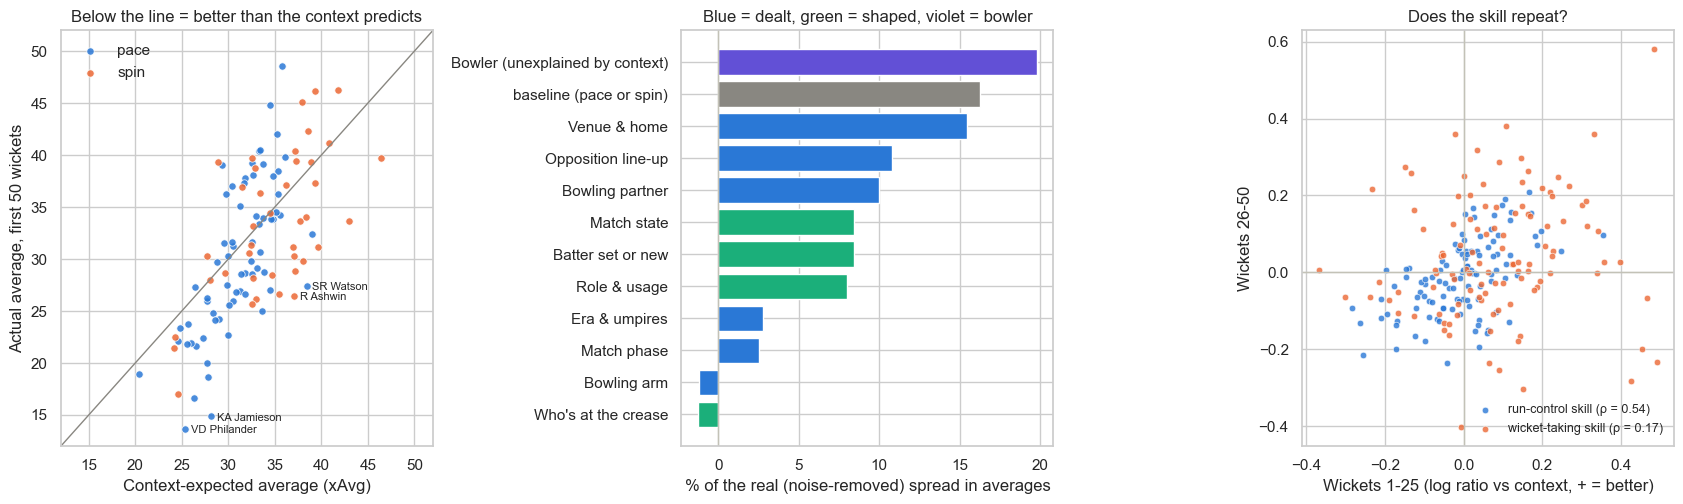

In [14]:
sns.set_theme(style='whitegrid', context='notebook')
TYPE_COLORS = {'pace': '#2a78d6', 'spin': '#eb6834'}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

# 1. Actual average vs what the context predicts
ax = axes[0]
for t, d in att.groupby('bowler_type'):
    ax.scatter(d['xAvg'], d['actual'], s=28, color=TYPE_COLORS[t], label=t, alpha=0.85, edgecolor='white', linewidth=0.6)
lim = [12, 52]
ax.plot(lim, lim, color='#898781', lw=1)
for _, r in att.nsmallest(4, 'bowler_effect').iterrows():
    ax.annotate(r['bowler'], (r['xAvg'], r['actual']), fontsize=8, xytext=(4, -3), textcoords='offset points')
ax.set(xlim=lim, ylim=lim, xlabel='Context-expected average (xAvg)', ylabel=f'Actual average, first {WICKET_WINDOW} wickets',
       title='Below the line = better than the context predicts')
ax.legend(frameon=False)

# 2. Where the real spread comes from
ax = axes[1]
vs = variance_shares.drop(['dealt', 'shaped']).sort_values('share of real variance')
colors = ['#6250d6' if i == 'bowler_effect' else '#1baf7a' if i in SHAPED else '#2a78d6' if i in DEALT else '#898781'
          for i in vs.index]
ax.barh(vs.index.str.replace('bowler_effect', 'Bowler (unexplained by context)'), 100 * vs['share of real variance'], color=colors)
ax.axvline(0, color='#c3c2b7', lw=1)
ax.set(xlabel='% of the real (noise-removed) spread in averages', title='Blue = dealt, green = shaped, violet = bowler')

# 3. Split-half: run control repeats, wicket-taking mostly doesn't
ax = axes[2]
for comp, c in [('run-control skill', '#2a78d6'), ('wicket-taking skill', '#eb6834')]:
    ax.scatter(h1[comp], h2.loc[h1.index, comp], s=22, color=c, alpha=0.8,
               label=f"{comp} (ρ = {split.loc[comp, 'reliability']:.2f})", edgecolor='white', linewidth=0.5)
ax.axhline(0, color='#c3c2b7', lw=1); ax.axvline(0, color='#c3c2b7', lw=1)
H = WICKET_WINDOW // 2
ax.set(xlabel=f'Wickets 1-{H} (log ratio vs context, + = better)', ylabel=f'Wickets {H + 1}-{WICKET_WINDOW}', title='Does the skill repeat?')
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 13. Export for the report

In [15]:
def records(frame, index_name=None):
    f = frame.reset_index() if index_name else frame
    if index_name:
        f = f.rename(columns={f.columns[0]: index_name})
    return json.loads(f.to_json(orient='records', double_precision=4))

EFFECT_VARS = ['home_x_type', 'country_x_type', 'lineup', 'partner', 'era', 'drs', 'umpire_lbw', 'toss_field',
               'innings_x_type', 'day_x_type', 'ball_age_x_type', 'new_ball2', 'opener_x_type', 'spell_over_x_type',
               'workload', 'set', 'bat_rel', 'bat_band', 'bat_hand_x_type', 'wkts_down', 'type']
white_ball = pd.concat({'all': wb_vs_test, 'odi10': wb_vs_test_10}, axis=1)
white_ball.columns = [f'{a}_{b}' for a, b in white_ball.columns]
bowler_out = att.join(bowlers[['tests', 'strike_rate', 'economy', 'first_test']]).join(
    full[['wicket-taking skill', 'run-control skill', 'overall skill']])
bowler_out['first_test'] = bowler_out['first_test'].dt.strftime('%Y-%m-%d')

results = {
    'meta': {
        'n_tests': int(matches['match_id'].nunique()),
        'n_tests_model': int(ctx['match_id'].nunique()),
        'n_deliveries_model': int(len(ctx)),
        'n_bowlers_model': int(ctx['bowler_id'].nunique()),
        'date_range': [str(matches['date'].min().date()), str(matches['date'].max().date())],
        'window': WICKET_WINDOW, 'sensitivity_window': SENSITIVITY_WINDOW,
        'full_coverage_from': str(FULL_COVERAGE_FROM.date()),
        'n_bowlers': int(len(bowlers)), 'n_pace': int((bowlers.bowler_type == 'pace').sum()),
        'n_spin': int((bowlers.bowler_type == 'spin').sum()),
        'league_avg': float(LEAGUE_AVG),
        'baseline_by_type': att.groupby('bowler_type')['baseline'].mean().round(2).to_dict(),
        'raw_half_reliability': list(map(float, raw_rel)), 'dealt_half_reliability': list(map(float, ctx_rel)),
        'n_pre_debut_odi': int((profile['pre-debut ODIs'] > 0).sum()),
        'n_neutral_tests': int(matches['host'].isna().sum()),
        'groups': GROUPS, 'dealt': DEALT, 'shaped': SHAPED,
    },
    'model_fit': records(model_fit, 'model'),
    'signal': records(signal, 'quantity'),
    'variance_shares': records(variance_shares, 'part'),
    'bowlers': records(bowler_out, 'bowler_id'),
    'split_half': records(split, 'component'),
    'prediction': records(pred_table, 'features'),
    'r2_ceiling': float(R2_CEILING),
    'white_ball': records(white_ball, 'pair'),
    'n_odi10': int(has_odi.sum()),
    'effects': records(effects[effects['variable'].isin(EFFECT_VARS)]),
    'sensitivity': records(sensitivity, 'measure'),
}
with open(RESULTS_FILE, 'w') as f:
    json.dump(results, f, indent=1)
print('Wrote', RESULTS_FILE)

Wrote factor_results.json
